# 02 · Preprocessing and novelty-aware CV folds

This notebook builds the inputs that every model shares:

1. **Preprocessor.** One `ColumnTransformer` (`src/preprocessing.py`): `OneHotEncoder(handle_unknown="ignore")` on `protocol_type`, `service`, `flag` and `StandardScaler` on the 38 numeric features, giving 122 features. Only the 41 predictors enter it; `label`, `difficulty_level`, `is_intrusion` and `attack_category` are rejected.
2. **Novelty-aware CV folds (inside `KDDTrain+` only).** The 22 training attack types are dealt round-robin (by size) into 5 groups. Fold *k* holds out attack group *k* plus a random fifth of the normal rows, so a model is always scored on attack types it never saw in training. This is the tuning scheme for every model and also yields out-of-fold scores for calibrating deployable thresholds.
3. **Leakage rule.** Each model notebook puts this preprocessor inside its `Pipeline`, so it is refit inside every fold and, for the final model, on `KDDTrain+` only. The copy saved here (fit on all of `KDDTrain+`) is identical to the one inside each final model.

**Outputs:** `scalars/preprocessor.joblib`, `scalars/preprocessor_feature_names.json`, `scalars/label_mapping.json`, `results/splits/attack_type_folds.json`, `results/splits/fold_of_row_seed42.npy`, `results/tables/novelty_folds.*`, `results/figures/preprocessing/*.png`.

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src.config import set_all_seeds
from src import controlled_framework as cf

rng = set_all_seeds(cf.SEED)
sns.set_theme(style="whitegrid", context="notebook")
print(f"primary seed={cf.SEED} | seeds={cf.SEEDS} | trials={cf.N_TRIALS} | novelty CV folds={cf.N_SPLITS} | "
      f"threshold={cf.THRESHOLD} | FPR budgets={cf.FPR_BUDGETS} | class_weight={cf.CLASS_WEIGHT}")

primary seed=42 | seeds=[42, 1, 2, 3, 4] | trials=25 | novelty CV folds=5 | threshold=0.5 | FPR budgets=[0.01, 0.02, 0.05] | class_weight=None


## 1. Load the official split

In [2]:
from src.data_loader import load_nsl_kdd
from src.preprocessing import split_features_target, create_preprocessor, save_preprocessor, DISALLOWED_COLUMNS

train_df, test_df = load_nsl_kdd(PROJECT_ROOT / cf.CFG["paths"]["train"], PROJECT_ROOT / cf.CFG["paths"]["test"])
X_train, y_train = split_features_target(train_df, "is_intrusion")
X_test, y_test = split_features_target(test_df, "is_intrusion")
assert not (set(X_train.columns) & DISALLOWED_COLUMNS)
print("KDDTrain+", X_train.shape, "| KDDTest+", X_test.shape)

KDDTrain+ (125973, 41) | KDDTest+ (22543, 41)


## 2. Leave-attack-types-out folds

In [3]:
paths = cf.save_fold_assignment(train_df, cf.SEED)
folds, groups = cf.novelty_folds(train_df, cf.SEED)
rows = []
for k, (tr, va) in enumerate(folds):
    held = sorted(t for t, g in groups.items() if g == k)
    va_lab = train_df["label"].iloc[va]
    assert not set(held) & set(train_df["label"].iloc[tr]), "held-out type leaked into training"
    rows.append({"fold": k, "held_out_attack_types": ", ".join(held), "n_types": len(held),
                 "held_out_attack_rows": int((va_lab != "normal").sum()), "held_out_normal_rows": int((va_lab == "normal").sum()),
                 "train_rows": len(tr)})
fold_tbl = pd.DataFrame(rows)
cf.save_table(fold_tbl, "novelty_folds")
print({k: str(v.relative_to(PROJECT_ROOT)) for k, v in paths.items()})
fold_tbl

{'attack_type_folds': 'results/splits/attack_type_folds.json', 'fold_of_row': 'results/splits/fold_of_row_seed42.npy'}


,fold,held_out_attack_types,n_types,held_out_attack_rows,held_out_normal_rows,train_rows
0,0,"guess_passwd, neptune, nmap, perl, rootkit",5,42773,13469,69731
1,1,"back, buffer_overflow, loadmodule, satan, spy",5,4630,13469,107874
2,2,"ftp_write, ipsweep, teardrop, warezmaster",4,4519,13469,107985
3,3,"land, multihop, portsweep, warezclient",4,3846,13468,108659
4,4,"imap, phf, pod, smurf",4,2862,13468,109643


Fold 0 holds out `neptune` (70% of training attacks), so its training set has far fewer attacks than the others; the fold AUCs are therefore expected to vary. Every row is held out exactly once.

## 3. Fit the shared preprocessor on `KDDTrain+` and check it

In [4]:
preprocessor = create_preprocessor(X_train).fit(X_train)
Z_train = preprocessor.transform(X_train)
Z_test = preprocessor.transform(X_test)
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]

n_cat = sum(1 for n in preprocessor.get_feature_names_out() if n.startswith("categorical__"))
checks = {
    "output width (train, test)": (Z_train.shape[1], Z_test.shape[1]),
    "one-hot / scaled columns": (n_cat, Z_train.shape[1] - n_cat),
    "NaN or inf in test output": bool(~np.isfinite(np.asarray(Z_test)).all()),
    "test categories unseen in train": sorted(set(X_test["service"]) - set(X_train["service"])),
    "train numeric mean ~0 (max |mean|)": float(np.abs(np.asarray(Z_train)[:, n_cat:].mean(axis=0)).max().round(6)),
}
assert Z_train.shape[1] == Z_test.shape[1] == 122
for k, v in checks.items():
    print(f"{k:40s} {v}")

output width (train, test)               (122, 122)
one-hot / scaled columns                 (84, 38)
NaN or inf in test output                False
test categories unseen in train          []
train numeric mean ~0 (max |mean|)       0.0


In [5]:
# The preprocessor rejects target / metadata columns
try:
    create_preprocessor(train_df[list(X_train.columns[:-1]) + ["difficulty_level"]])
    raise AssertionError("difficulty_level was accepted")
except ValueError as e:
    print("rejected as expected:", str(e)[:90], "...")

rejected as expected: Forbidden target or metadata column(s) detected in X_train: ['difficulty_level']. The prep ...


## 4. Save the fitted preprocessor, feature names and label mapping (`scalars/`)

In [6]:
cf.ensure_dirs(cf.SCALARS_DIR)
prep_path = save_preprocessor(preprocessor, cf.SCALARS_DIR / "preprocessor.joblib")
(cf.SCALARS_DIR / "preprocessor_feature_names.json").write_text(json.dumps(
    {"n_features": len(feature_names), "fitted_on": "KDDTrain+ (125,973 rows)", "feature_names": feature_names}, indent=2))
(cf.SCALARS_DIR / "label_mapping.json").write_text(json.dumps(
    {"0": "normal", "1": "attack (any non-normal label)", "target_column": "is_intrusion", "source_column": "label"}, indent=2))
print("saved:", prep_path.relative_to(PROJECT_ROOT), "+ feature names + label mapping")

saved: scalars/preprocessor.joblib + feature names + label mapping


## 5. Held-out composition per fold

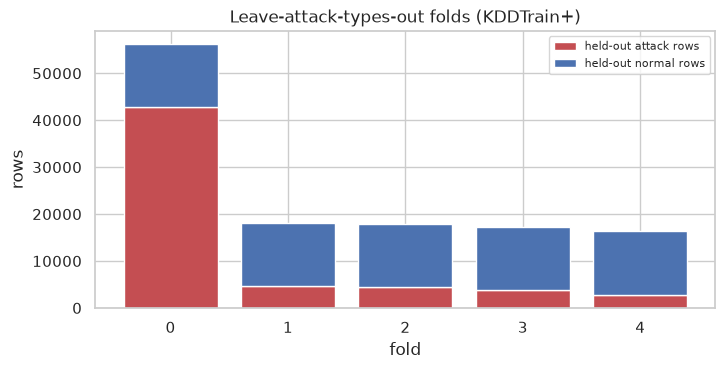

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(fold_tbl["fold"], fold_tbl["held_out_attack_rows"], color="#C44E52", label="held-out attack rows")
ax.bar(fold_tbl["fold"], fold_tbl["held_out_normal_rows"], bottom=fold_tbl["held_out_attack_rows"], color="#4C72B0", label="held-out normal rows")
ax.set_xlabel("fold"); ax.set_ylabel("rows"); ax.legend(fontsize=8)
ax.set_title("Leave-attack-types-out folds (KDDTrain+)")
cf.save_figure(fig, "preprocessing", "novelty_folds"); plt.show()